In [1]:
import math
import time
import pandas as pd
import tensorflow as tf
import keras
from dataclasses import dataclass
from pathlib import Path
from cnnClassifier import logger
from cnnClassifier.constants import *
from cnnClassifier.utils.common import (
    read_yaml, create_directories, make_dataset, compute_class_weights, set_trainable, save_model, WarmupCosine, plot_history,
)

I0000 00:00:1793791345.646972   89910 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import os
print(os.environ.get("LD_LIBRARY_PATH"))

/home/nima/Projects/ML-Project-Casting_Classification/Project/.venv/lib/python3.12/site-packages/nvidia/cublas/lib:/home/nima/Projects/ML-Project-Casting_Classification/Project/.venv/lib/python3.12/site-packages/nvidia/cuda_cupti/lib:/home/nima/Projects/ML-Project-Casting_Classification/Project/.venv/lib/python3.12/site-packages/nvidia/cuda_nvrtc/lib:/home/nima/Projects/ML-Project-Casting_Classification/Project/.venv/lib/python3.12/site-packages/nvidia/cuda_runtime/lib:/home/nima/Projects/ML-Project-Casting_Classification/Project/.venv/lib/python3.12/site-packages/nvidia/cudnn/lib:/home/nima/Projects/ML-Project-Casting_Classification/Project/.venv/lib/python3.12/site-packages/nvidia/cufft/lib:/home/nima/Projects/ML-Project-Casting_Classification/Project/.venv/lib/python3.12/site-packages/nvidia/curand/lib:/home/nima/Projects/ML-Project-Casting_Classification/Project/.venv/lib/python3.12/site-packages/nvidia/cusolver/lib:/home/nima/Projects/ML-Project-Casting_Classification/Project/.ven

In [3]:
%pwd

'/home/nima/Projects/ML-Project-Casting_Classification/Project/research'

In [4]:
os.chdir("../")

In [5]:
%pwd

'/home/nima/Projects/ML-Project-Casting_Classification/Project'

In [6]:
@dataclass(frozen=True)
class TrainingConfig:
    root_dir: Path
    trained_model_path: Path
    updated_base_model_path: Path
    splits_dir: Path
    phase1_weights_path: Path
    phase2_weights_path: Path


@dataclass(frozen=True)
class TrainingParams:
    IMG_SIZE: list
    BATCH_SIZE: int
    EPOCHS_P1: int
    EPOCHS_P2: int
    LEARNINGRATE_P1: float
    LEARNINGRATE_P2: float
    WARMUP_EPOCHS_P1: int
    WARMUP_EPOCHS_P2: int
    N_UNFREEZE: int
    PATIENCE: int
    ROTATION_FACTOR: float
    BRIGHTNESS_FACTOR: float
    CONTRAST_FACTOR: float

@dataclass(frozen=True)
class PrepareCallbacksConfig:
    root_dir: Path
    tensorboard_root_log_dir: Path
    checkpoint_phase1_filepath: Path
    checkpoint_phase2_filepath: Path

In [7]:
class PrepareCallback:
    def __init__(self, config: PrepareCallbacksConfig):
        self.config = config

    def _checkpoint_path(self, phase: int) -> Path:
        return {1: self.config.checkpoint_phase1_filepath,
                2: self.config.checkpoint_phase2_filepath}[phase]

    def get_callbacks(self, phase: int, patience: int = 5) -> list:
        if phase not in (1, 2):
            raise ValueError("phase must be 1 or 2")
        timestamp = time.strftime("%Y-%m-%d-%H-%M-%S")
        tb_dir = Path(self.config.tensorboard_root_log_dir) / f"phase{phase}" / f"tb_logs_at_{timestamp}"
        return [
            tf.keras.callbacks.TensorBoard(log_dir=str(tb_dir)),
            tf.keras.callbacks.ModelCheckpoint(
                filepath=str(self._checkpoint_path(phase)),
                monitor="val_loss", mode="min",
                save_best_only=True, save_weights_only=True),   # the phase handoff file
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss", mode="min",
                patience=patience, restore_best_weights=True),
        ]

In [ ]:
class ConfigurationManager:
    def __init__(self, config_filepath=CONFIG_FILE_PATH, params_filepath=PARAMS_FILE_PATH):
        self.config = read_yaml(config_filepath)
        self.params = read_yaml(params_filepath)
        create_directories([self.config.artifacts_root])

    def get_prepare_callback_config(self) -> PrepareCallbacksConfig:
                config = self.config.prepare_callbacks
                create_directories([
                    Path(config.checkpoint_phase1_filepath).parent,
                    Path(config.checkpoint_phase2_filepath).parent,
                    Path(config.tensorboard_root_log_dir),
                ])
                return PrepareCallbacksConfig(
                    root_dir=Path(config.root_dir),
                    tensorboard_root_log_dir=Path(config.tensorboard_root_log_dir),
                    checkpoint_phase1_filepath=Path(config.checkpoint_phase1_filepath),
                    checkpoint_phase2_filepath=Path(config.checkpoint_phase2_filepath),
                )
    
    def get_training_config(self) -> TrainingConfig:
        training = self.config.training
        create_directories([Path(training.root_dir)])
        return TrainingConfig(
            root_dir=Path(training.root_dir),
            trained_model_path=Path(training.trained_model_path),
            updated_base_model_path=Path(self.config.prepare_base_model.updated_base_model_path),
            splits_dir=Path(training.splits_dir),
            # same yaml keys the callbacks write to -> single source of truth
            phase1_weights_path=Path(self.config.prepare_callbacks.checkpoint_phase1_filepath),
            phase2_weights_path=Path(self.config.prepare_callbacks.checkpoint_phase2_filepath),
        )

    def get_training_params(self) -> TrainingParams:
        p = self.params
        return TrainingParams(
            IMG_SIZE=p.IMG_SIZE, BATCH_SIZE=p.BATCH_SIZE,
            EPOCHS_P1=p.EPOCHS_P1, EPOCHS_P2=p.EPOCHS_P2,
            LEARNINGRATE_P1=p.LEARNINGRATE_P1, LEARNINGRATE_P2=p.LEARNINGRATE_P2,
            WARMUP_EPOCHS_P1=p.WARMUP_EPOCHS_P1, WARMUP_EPOCHS_P2=p.WARMUP_EPOCHS_P2,
            N_UNFREEZE=p.N_UNFREEZE, PATIENCE=p.PATIENCE,
            ROTATION_FACTOR=p.ROTATION_FACTOR, BRIGHTNESS_FACTOR=p.BRIGHTNESS_FACTOR,
            CONTRAST_FACTOR=p.CONTRAST_FACTOR,
        )  

In [9]:
class Training:
    def __init__(self, config: TrainingConfig, params: TrainingParams):
        self.config = config
        self.params = params
        self.img_size = tuple(params.IMG_SIZE)

    # ---------- model ----------
    def get_base_model(self):
        """Load the architecture from 02 (uncompiled) and locate the nested MobileNetV2."""
        self.model = keras.models.load_model(self.config.updated_base_model_path, compile=False)
        self.base_model = next(l for l in self.model.layers if isinstance(l, keras.Model))

    # ---------- data ----------
    def build_augmenter(self, seed: int = 42) -> keras.Sequential:
        return keras.Sequential([
            keras.layers.RandomFlip("horizontal_and_vertical", seed=seed),
            keras.layers.RandomRotation(self.params.ROTATION_FACTOR, fill_mode="reflect", seed=seed),
            keras.layers.RandomBrightness(self.params.BRIGHTNESS_FACTOR, value_range=(0.0, 1.0), seed=seed),
            keras.layers.RandomContrast(self.params.CONTRAST_FACTOR, seed=seed),
        ], name="augmenter")
    

    def build_datasets(self):
        """Train (augmented) and val only. The test split is reserved for the evaluation stage."""
        splits = Path(self.config.splits_dir)
        train_df = pd.read_csv(splits / "train.csv")
        self.class_weights = compute_class_weights(train_df)
        self.steps_per_epoch = math.ceil(len(train_df) / self.params.BATCH_SIZE)

        self.train_ds = make_dataset(splits / "train.csv", self.img_size, self.params.BATCH_SIZE,
                                    training=True, augmenter=self.build_augmenter())
        self.val_ds = make_dataset(splits / "val.csv", self.img_size, self.params.BATCH_SIZE)
        logger.info(f"datasets ready | steps/epoch={self.steps_per_epoch} | class weights={self.class_weights}")
        

    # ---------- phase-specific training setup ----------
    def _create_lr_schedule(self, phase: int) -> WarmupCosine:
        p = self.params
        if phase == 1:
            epochs, peak, warmup_epochs, final_lr = p.EPOCHS_P1, p.LEARNINGRATE_P1, p.WARMUP_EPOCHS_P1, 1e-6
        else:
            epochs, peak, warmup_epochs, final_lr = p.EPOCHS_P2, p.LEARNINGRATE_P2, p.WARMUP_EPOCHS_P2, 1e-7
        return WarmupCosine(peak_lr=peak,
                            total_steps=epochs * self.steps_per_epoch,
                            warmup_steps=warmup_epochs * self.steps_per_epoch,
                            final_lr=final_lr)

    def _compile(self, lr_schedule) -> None:
        self.model.compile(
            jit_compile=False,
            optimizer=keras.optimizers.Adam(learning_rate=lr_schedule),   # fresh optimizer per phase
            loss="binary_crossentropy",
            metrics=[
                keras.metrics.BinaryAccuracy(name="acc", threshold=0.5),
                keras.metrics.AUC(name="auc"),
                keras.metrics.Precision(name="precision", thresholds=0.5),
                keras.metrics.Recall(name="recall", thresholds=0.5),
            ],
        )

    def run_phase(self, phase: int, callback_list: list):
        """Phase 1: train the head, base frozen. Phase 2: fine-tune the top layers from the phase-1 weights."""
        if phase not in (1, 2):
            raise ValueError("phase must be 1 or 2")

        if phase == 1:
            set_trainable(self.base_model, freeze_all=True)
            epochs = self.params.EPOCHS_P1
            best_weights = self.config.phase1_weights_path
        else:
            # start from the best phase-1 head, also after a kernel restart
            self.model.load_weights(self.config.phase1_weights_path)
            set_trainable(self.base_model, freeze_all=False, n_unfreeze=self.params.N_UNFREEZE)
            epochs = self.params.EPOCHS_P2
            best_weights = self.config.phase2_weights_path

        self._compile(self._create_lr_schedule(phase))   # required after changing trainable flags
        self.model.summary()

        history = self.model.fit(
            self.train_ds,
            validation_data=self.val_ds,
            epochs=epochs,
            class_weight=self.class_weights,
            callbacks=callback_list,
        )

        # the checkpoint file is the source of truth for "best epoch" of this phase
        self.model.load_weights(best_weights)
        logger.info(f"phase {phase} finished, best weights reloaded from {best_weights}")
        return history

    def save_trained_model(self):
        """Full model (architecture + weights) for evaluation and inference."""
        save_model(path=self.config.trained_model_path, model=self.model)
        logger.info(f"trained model saved to {self.config.trained_model_path}")

In [10]:
try:
    # cell A: setup
    config = ConfigurationManager()
    params = config.get_training_params()
    training = Training(config=config.get_training_config(), params=params)
    training.get_base_model()
    training.build_datasets()
    prepare_callbacks = PrepareCallback(config=config.get_prepare_callback_config())   
     
except Exception as e:
    raise e

[2026-11-04 12:22:28,676: INFO: common: yaml file: config/config.yaml loaded successfully]
[2026-11-04 12:22:28,680: INFO: common: yaml file: params.yaml loaded successfully]
[2026-11-04 12:22:28,681: INFO: common: created directory at: artifacts]
[2026-11-04 12:22:28,683: INFO: common: created directory at: artifacts/training]


W0000 00:00:1793791348.879635   89910 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
I0000 00:00:1793791348.879877   89910 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3414 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1050, pci bus id: 0000:01:00.0, compute capability: 6.1


[2026-11-04 12:22:33,126: INFO: 881301789: datasets ready | steps/epoch=33 | class weights={1: 0.832, 0: 1.2530120481927711}]
[2026-11-04 12:22:33,127: INFO: common: created directory at: artifacts/prepare_callbacks/checkpoint_dir]
[2026-11-04 12:22:33,128: INFO: common: created directory at: artifacts/prepare_callbacks/checkpoint_dir]
[2026-11-04 12:22:33,128: INFO: common: created directory at: artifacts/prepare_callbacks/tensorboard_log_dir]


Model: "updated_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ gray_input          │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gray_to_rgb         │ (None, 224, 224,  │          0 │ gray_input[0][0], │
│ (Concatenate)       │ 3)                │            │ gray_input[0][0], │
│                     │                   │            │ gray_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ to_minus1_1         │ (None, 224, 224,  │          0 │ gray_to_rgb[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ to_minus1_1[0][0] │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1280)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ defect_prob (Dense) │ (None, 1)         │      1,281 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/20


... (4 outputs left out)

I0000 00:00:1793791438.751256   90399 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 15987122187569279913


33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 177ms/step - acc: 0.8837 - auc: 0.9610 - loss: 0.2821 - precision: 0.9500 - recall: 0.8512 - val_acc: 0.9308 - val_auc: 0.9889 - val_loss: 0.2133 - val_precision: 0.9600 - val_recall: 0.9231
Epoch 13/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 177ms/step - acc: 0.8827 - auc: 0.9572 - loss: 0.2813 - precision: 0.9451 - recall: 0.8544 - val_acc: 0.9385 - val_auc: 0.9900 - val_loss: 0.2108 - val_precision: 0.9487 - val_recall: 0.9487
Epoch 14/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 177ms/step - acc: 0.8962 - auc: 0.9594 - loss: 0.2793 - precision: 0.9496 - recall: 0.8736 - val_acc: 0.9385 - val_auc: 0.9896 - val_loss: 0.2075 - val_precision: 0.9605 - val_recall: 0.9359
Epoch 15/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - acc: 0.8954 - auc: 0.9659 - loss: 0.2707 - precision: 0.9500 - recall: 0.8729

I0000 00:00:1793791456.869806   90399 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 15987122187569279913


33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 178ms/step - acc: 0.8875 - auc: 0.9620 - loss: 0.2783 - precision: 0.9425 - recall: 0.8656 - val_acc: 0.9385 - val_auc: 0.9898 - val_loss: 0.2050 - val_precision: 0.9730 - val_recall: 0.9231
Epoch 16/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 177ms/step - acc: 0.8798 - auc: 0.9603 - loss: 0.2776 - precision: 0.9371 - recall: 0.8576 - val_acc: 0.9385 - val_auc: 0.9901 - val_loss: 0.2047 - val_precision: 0.9605 - val_recall: 0.9359
Epoch 17/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 177ms/step - acc: 0.8827 - auc: 0.9574 - loss: 0.2840 - precision: 0.9227 - recall: 0.8784 - val_acc: 0.9308 - val_auc: 0.9901 - val_loss: 0.2038 - val_precision: 0.9600 - val_recall: 0.9231
Epoch 18/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 177ms/step - acc: 0.8904 - auc: 0.9633 - loss: 0.2697 - precision: 0.9353 - recall: 0.8784 - val_acc: 0.9385 - val_auc: 0.9901 - val_loss: 0.2031 - val_precision: 0.9730 - val_recall: 0.9231
Epoch 19/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 163ms/step - acc: 0.8894 - auc: 0.9581

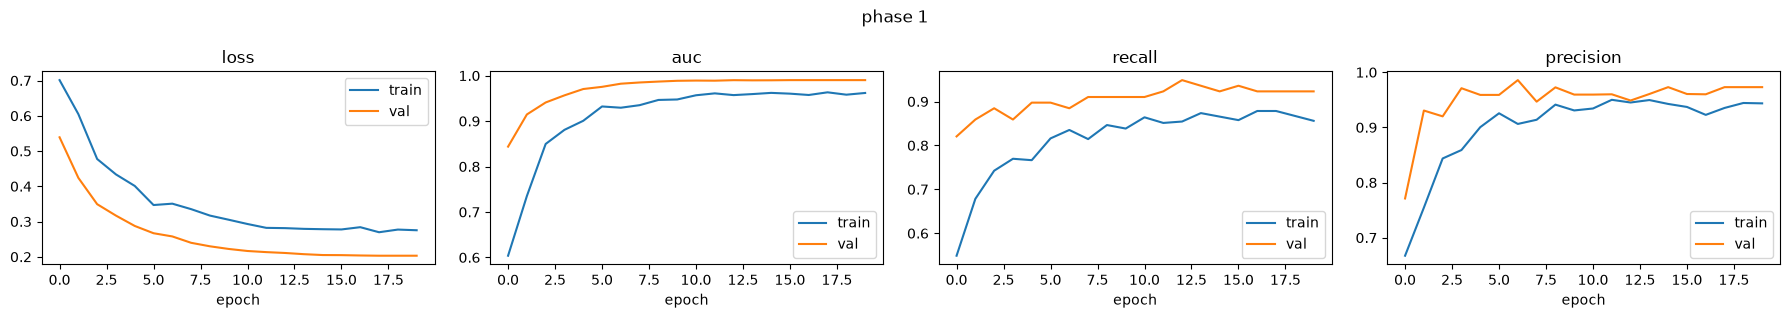

In [11]:
try:
    # cell B: phase 1
    history_p1 = training.run_phase(1, prepare_callbacks.get_callbacks(phase=1, patience=params.PATIENCE))
    plot_history(history_p1, "phase 1")
    
except Exception as e:
    raise e

Model: "updated_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ gray_input          │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gray_to_rgb         │ (None, 224, 224,  │          0 │ gray_input[0][0], │
│ (Concatenate)       │ 3)                │            │ gray_input[0][0], │
│                     │                   │            │ gray_input[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ to_minus1_1         │ (None, 224, 224,  │          0 │ gray_to_rgb[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ to_minus1_1[0][0] │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ mobilenetv2_1.00… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1280)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ defect_prob (Dense) │ (None, 1)         │      1,281 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,512,001 (5.77 MB)

 Non-trainable params: 747,264 (2.85 MB)

Epoch 1/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 14s 251ms/step - acc: 0.9010 - auc: 0.9652 - loss: 0.2440 - precision: 0.9469 - recall: 0.8848 - val_acc: 0.9385 - val_auc: 0.9961 - val_loss: 0.1697 - val_precision: 1.0000 - val_recall: 0.8974
Epoch 2/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 7s 199ms/step - acc: 0.9423 - auc: 0.9854 - loss: 0.1477 - precision: 0.9639 - recall: 0.9392 - val_acc: 0.9769 - val_auc: 0.9995 - val_loss: 0.0682 - val_precision: 0.9747 - val_recall: 0.9872
Epoch 3/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 7s 198ms/step - acc: 0.9644 - auc: 0.9943 - loss: 0.0970 - precision: 0.9820 - recall: 0.9584 - val_acc: 0.9923 - val_auc: 0.9995 - val_loss: 0.0539 - val_precision: 0.9873 - val_recall: 1.0000
Epoch 4/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 7s 197ms/step - acc: 0.9779 - auc: 0.9956 - loss: 0.0682 - precision: 0.9951 - recall: 0.9680 - val_acc: 0.9923 - val_auc: 0.9998 - val_loss: 0.0353 - val_precision: 0.9873 - val_recall: 1.0000
Epoch 5/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 184ms/step - acc: 0.9837 - auc

... (14 outputs left out)

I0000 00:00:1793791656.031793   91234 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 6834729378527391860
I0000 00:00:1793791656.031819   91234 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 15287424321853252436


33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 179ms/step - acc: 1.0000 - auc: 1.0000 - loss: 0.0023 - precision: 1.0000 - recall: 1.0000 - val_acc: 1.0000 - val_auc: 1.0000 - val_loss: 0.0036 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 26/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 7s 200ms/step - acc: 0.9990 - auc: 1.0000 - loss: 0.0032 - precision: 1.0000 - recall: 0.9984 - val_acc: 1.0000 - val_auc: 1.0000 - val_loss: 0.0029 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 27/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 7s 201ms/step - acc: 0.9990 - auc: 1.0000 - loss: 0.0031 - precision: 1.0000 - recall: 0.9984 - val_acc: 1.0000 - val_auc: 1.0000 - val_loss: 0.0027 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 28/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 7s 198ms/step - acc: 1.0000 - auc: 1.0000 - loss: 0.0011 - precision: 1.0000 - recall: 1.0000 - val_acc: 1.0000 - val_auc: 1.0000 - val_loss: 0.0027 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 29/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step - acc: 1.0000 - auc: 1.0000

I0000 00:00:1793791682.584057   91234 local_rendezvous.cc:432] Local rendezvous recv item cancelled. Key hash: 6834729378527391860


33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 182ms/step - acc: 1.0000 - auc: 1.0000 - loss: 0.0016 - precision: 1.0000 - recall: 1.0000 - val_acc: 1.0000 - val_auc: 1.0000 - val_loss: 0.0027 - val_precision: 1.0000 - val_recall: 1.0000
Epoch 30/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 183ms/step - acc: 0.9981 - auc: 1.0000 - loss: 0.0034 - precision: 1.0000 - recall: 0.9968 - val_acc: 1.0000 - val_auc: 1.0000 - val_loss: 0.0027 - val_precision: 1.0000 - val_recall: 1.0000
[2026-11-04 12:28:10,046: INFO: 881301789: phase 2 finished, best weights reloaded from artifacts/prepare_callbacks/checkpoint_dir/phase2_best.weights.h5]


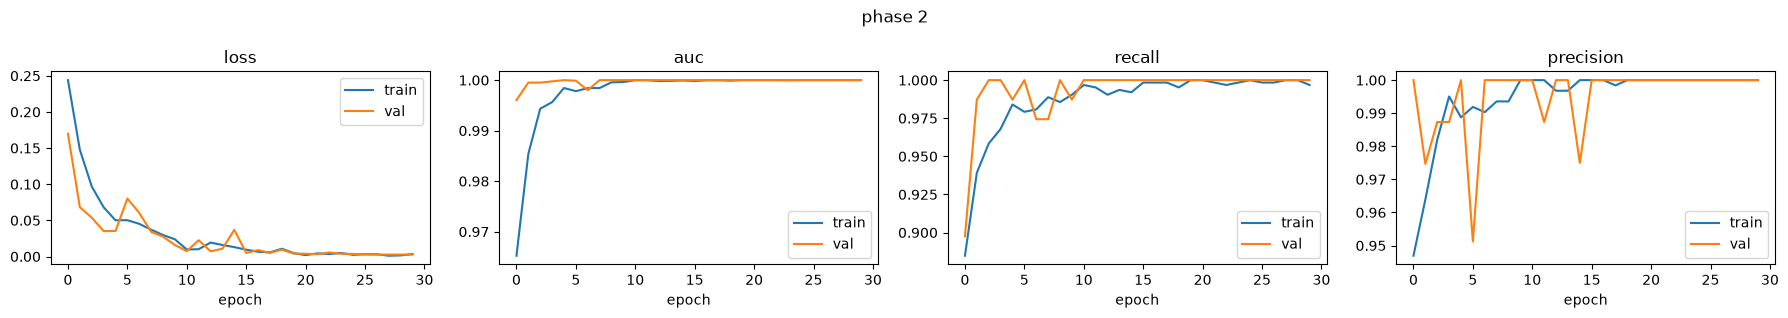

[2026-11-04 12:28:10,973: INFO: 881301789: trained model saved to artifacts/training/model.keras]


In [12]:
try:
    # cell C: phase 2
    history_p2 = training.run_phase(2, prepare_callbacks.get_callbacks(phase=2, patience=params.PATIENCE))
    plot_history(history_p2, "phase 2")
    training.save_trained_model()
    
except Exception as e:
    raise e